## Exploratory Data Analysis (EDA)

In [8]:
import pandas as pd #install pandas
import matplotlib.pyplot as plt #install matplotlib
from wordcloud import WordCloud #install wordcloud
#import emoji
from collections import Counter
import re
from nltk import ngrams #install nltk
import arabic_reshaper
from bidi.algorithm import get_display
import re

* Read CSV File

In [ ]:
df = pd.read_csv('../../data/raw/complete2_unnormalized.csv') 
df.head()

,review,language,label
0,👍👍👍,emoji,positive
1,😍💖,emoji,positive
2,👍,emoji,positive
3,👌👍,emoji,positive
4,👍👍👍👍,emoji,positive


* Labels Checking 

In [458]:
# Checking all the dataframe's labels ('positive', 'negative', or 'neutral')
df['label'].unique()

array(['positive', 'neutral', 'negative'], dtype=object)

* Replacing Misspelled Labels

In [459]:
# label_mapping = {
#     'negative ': 'negative',
#     'nagtive': 'negative',
#     'neutal': 'neutral',
#     'netural': 'neutral',
#     'nautral': 'neutral'
# }

# df['label'] = df['label'].replace(label_mapping)

* Count of Positive, Negative, and Neutral (Arabic Reviews)

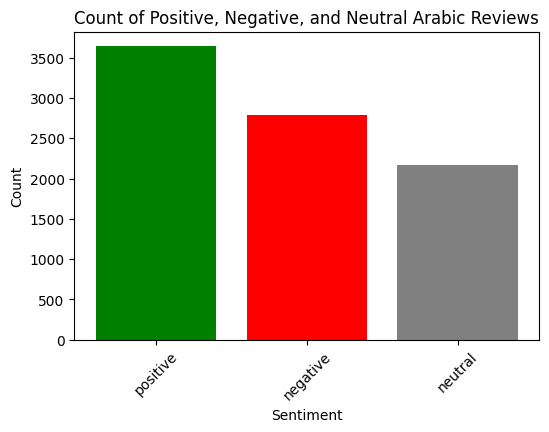

In [460]:
# Filter for Arabic reviews
arabic_reviews = df[df['language'] == 'ar']

# Count sentiments
sentiment_counts = arabic_reviews['label'].value_counts()

# Create a bar graph
plt.figure(figsize=(6, 4))
plt.bar(sentiment_counts.index, sentiment_counts.values, color=['green', 'red', 'gray'])
plt.xlabel('Sentiment')
plt.ylabel('Count')
plt.title('Count of Positive, Negative, and Neutral Arabic Reviews')
plt.xticks(rotation=45)
plt.show()

* Count of Positive, Negative, and Neutral (English Reviews)

* Sentiment Comparison: Arabic vs. English 

In [463]:
# Initialize dictionaries to hold sentiment counts for each language
sentiment_counts = {
    'Arabic': df[df['review'].str.contains('[\u0600-\u06FF]', na=False)]['label'].value_counts(),
    'English': df[~df['review'].str.contains('[\u0600-\u06FF]', na=False)]['label'].value_counts()
}

# Create a DataFrame for easier plotting
comparison_df = pd.DataFrame(sentiment_counts).fillna(0)

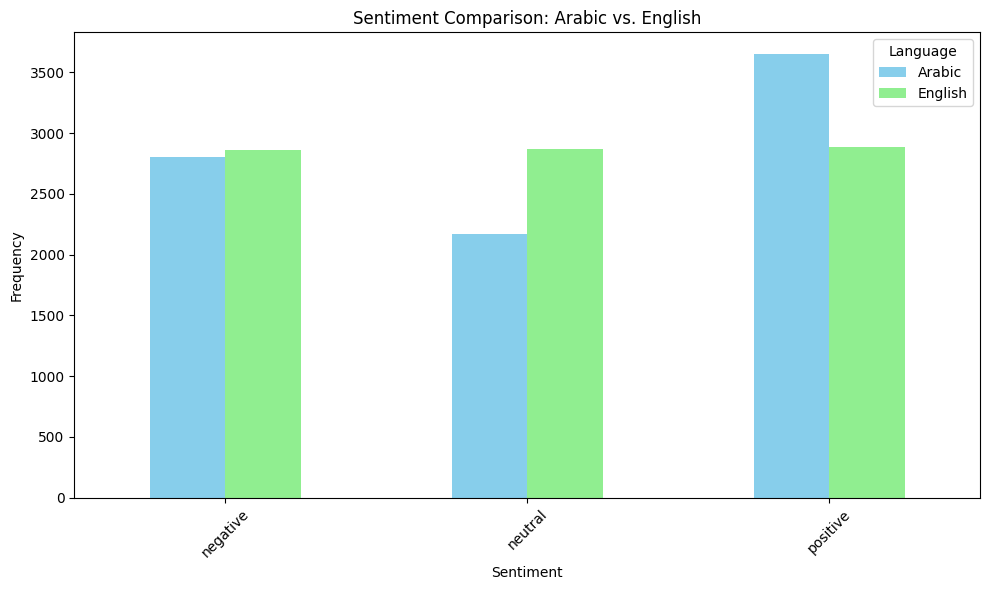

          Arabic  English
label                    
negative    2802     2858
neutral     2171     2865
positive    3646     2888


In [464]:
# Plotting the sentiment comparison
comparison_df.plot(kind='bar', figsize=(10, 6), color=['skyblue', 'lightgreen'])
plt.title('Sentiment Comparison: Arabic vs. English')
plt.xlabel('Sentiment')
plt.ylabel('Frequency')
plt.xticks(rotation=0)
plt.legend(title='Language')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Display the counts
print(comparison_df)

* Count of Positive, Negative, and Neutral Reviews (Both Arabic and English)

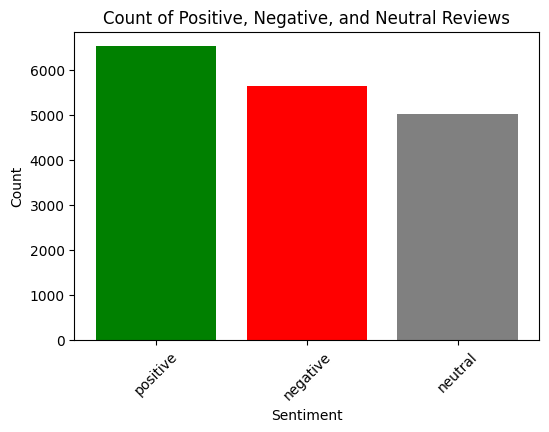

In [465]:
# Count sentiments (Both Arabic and English)
full_sentiment_counts = df['label'].value_counts()

# Create a bar graph
plt.figure(figsize=(6, 4))
plt.bar(full_sentiment_counts.index, full_sentiment_counts.values, color=['green', 'red', 'gray'])
plt.xlabel('Sentiment')
plt.ylabel('Count')
plt.title('Count of Positive, Negative, and Neutral Reviews')
plt.xticks(rotation=45)
plt.show()

* Count of Reviews in Arabic and English

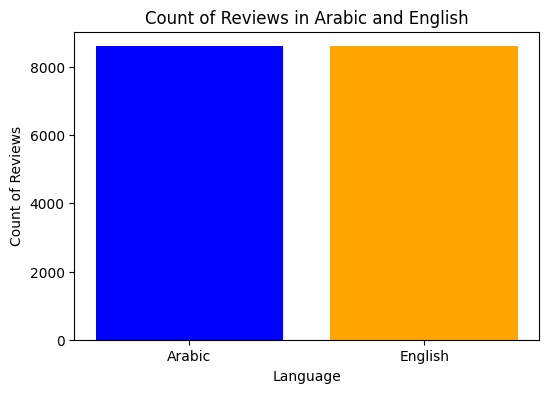

In [466]:
# Count reviews per language (Arabic and English)
language_counts = df['language'].value_counts().loc[['ar', 'en']]

# Rename the index for better readability
language_counts.index = ['Arabic', 'English']

# Create a bar graph
plt.figure(figsize=(6, 4))
plt.bar(language_counts.index, language_counts.values, color=['blue', 'orange'])
plt.xlabel('Language')
plt.ylabel('Count of Reviews')
plt.title('Count of Reviews in Arabic and English')
plt.show()

* Word Counts for Arabic Reviews (Max, Min, and Average) 

In [467]:
# Calculate word counts for Arabic reviews
arabic_reviews = df[df['review'].str.contains('[\u0600-\u06FF]', na=False)]
arabic_word_counts = arabic_reviews['review'].apply(lambda x: len(str(x).split()))

# Calculate max, min, and average word count for Arabic
arabic_max_length = arabic_word_counts.max()
arabic_min_length = arabic_word_counts.min()
arabic_avg_length = arabic_word_counts.mean()

In [468]:
# Prepare data for the Arabic table
arabic_stats_data = {
    'Statistic': ['Maximum', 'Minimum', 'Average'],
    'Word Count': [arabic_max_length, arabic_min_length, arabic_avg_length]
}

# Create a DataFrame for Arabic statistics
arabic_stats_df = pd.DataFrame(arabic_stats_data)

# Display the Arabic statistics table
print("Arabic Reviews Word Count Statistics:")
print(arabic_stats_df)

Arabic Reviews Word Count Statistics:
  Statistic  Word Count
0   Maximum  225.000000
1   Minimum    1.000000
2   Average   14.436942


* Word Counts for English Reviews (Max, Min, and Average)

In [469]:
# Calculate word counts for English reviews
english_reviews = df[~df['review'].str.contains('[\u0600-\u06FF]', na=False)]
english_word_counts = english_reviews['review'].apply(lambda x: len(str(x).split()))

# Calculate max, min, and average word count for English
english_max_length = english_word_counts.max()
english_min_length = english_word_counts.min()
english_avg_length = english_word_counts.mean()

In [470]:
# Prepare data for the English table
english_stats_data = {
    'Statistic': ['Maximum', 'Minimum', 'Average'],
    'Word Count': [english_max_length, english_min_length, english_avg_length]
}

# Create a DataFrame for English statistics
english_stats_df = pd.DataFrame(english_stats_data)

# Display the English statistics table
print("\nEnglish Reviews Word Count Statistics:")
print(english_stats_df)


English Reviews Word Count Statistics:
  Statistic  Word Count
0   Maximum  189.000000
1   Minimum    0.000000
2   Average   10.363721


In [10]:
# Calculate review lengths
review_lengths = df['review'].apply(lambda x: len(str(x).split())) # Count words
average_length = review_lengths.mean()
max_length = review_lengths.max()

print(f"Average length: {average_length}")
print(f"Maximum length: {max_length}")

Average length: 12.401508995937318
Maximum length: 225


count    17230.000000
mean        12.401277
std         14.023428
min          0.000000
25%          4.000000
50%          7.000000
75%         16.000000
max        225.000000
Name: review, dtype: float64


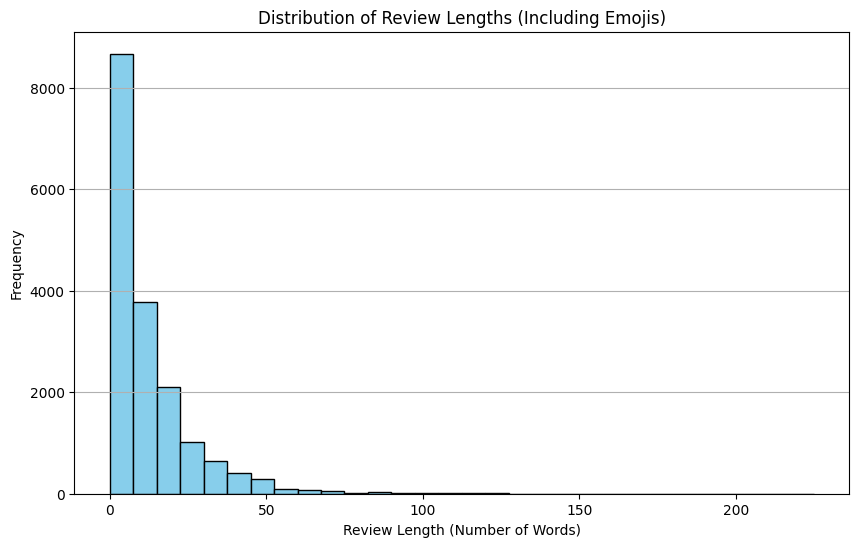

In [11]:
# Calculate the length of each review, counting words including emojis
review_length = df['review'].fillna('').astype(str).apply(lambda x: len(x.split()))

# Get descriptive statistics
length_stats = review_length.describe()
print(length_stats)

# Plot a histogram of review lengths
plt.figure(figsize=(10, 6))
plt.hist(review_length, bins=30, color='skyblue', edgecolor='black')
plt.title('Distribution of Review Lengths (Including Emojis)')
plt.xlabel('Review Length (Number of Words)')
plt.ylabel('Frequency')
plt.grid(axis='y')
plt.show()

* Word Clouds for Each Sentiment Class

C:\Users\Nadaf\AppData\Local\Temp\ipykernel_32364\2222935930.py:12: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  text = ' '.join(en_df[df['label'] == sentiment]['review'].dropna().astype(str))
C:\Users\Nadaf\AppData\Local\Temp\ipykernel_32364\2222935930.py:12: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  text = ' '.join(en_df[df['label'] == sentiment]['review'].dropna().astype(str))
C:\Users\Nadaf\AppData\Local\Temp\ipykernel_32364\2222935930.py:12: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  text = ' '.join(en_df[df['label'] == sentiment]['review'].dropna().astype(str))


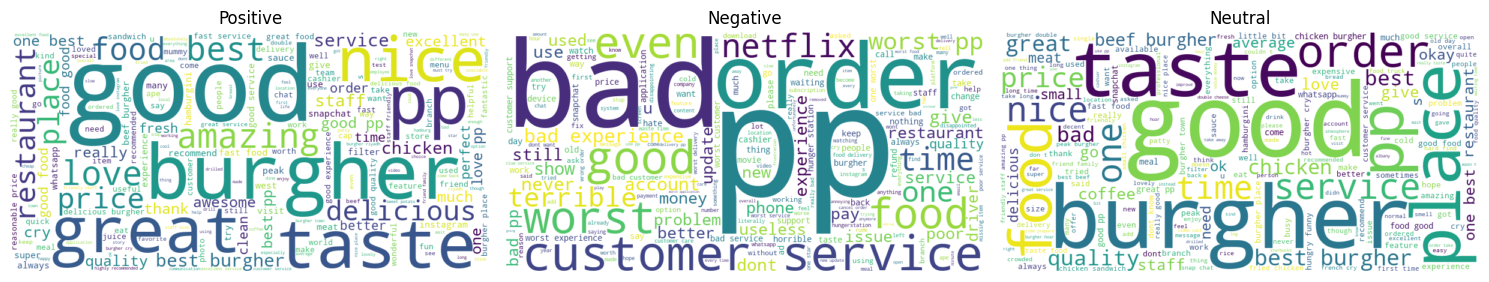

In [12]:
# Create a word cloud for each sentiment class (English)
en_df = df[df['language'] == 'en']
sentiments = en_df['label'].unique()

# Set up the plot
plt.figure(figsize=(15, 10))

for i, sentiment in enumerate(sentiments):
    plt.subplot(1, len(sentiments), i + 1)
    
    # Filter reviews for the current sentiment, considering both Arabic and English
    text = ' '.join(en_df[df['label'] == sentiment]['review'].dropna().astype(str))
    
    # Generate the word cloud
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text)
    
    # Display the word cloud
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')  # Hide axes
    plt.title(sentiment.capitalize())  # Title for each sentiment

# Show the plot
plt.tight_layout()
plt.show()

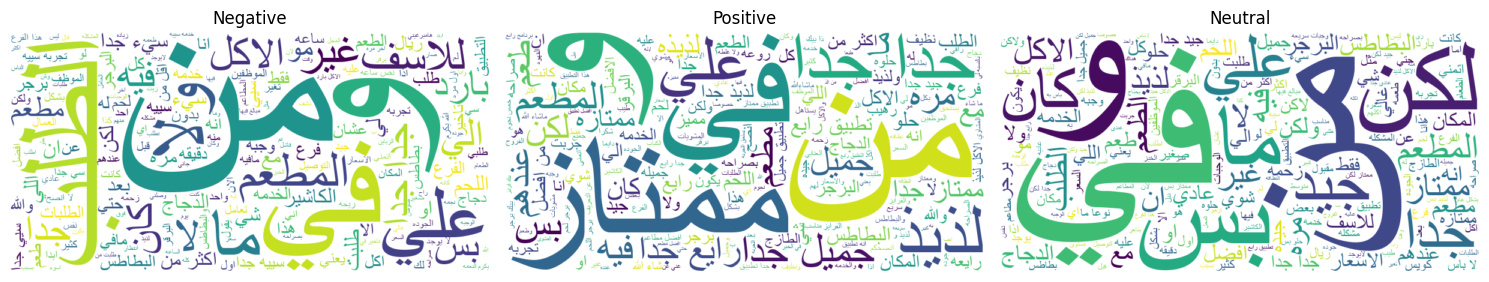

In [10]:
def clean_arabic_text(text):
    """Remove emojis and non-Arabic characters from the text."""
    # Regex to keep Arabic characters and spaces only
    cleaned_text = re.sub(r'[^\u0600-\u06FF\s]', '', text)
    return cleaned_text.strip()

# Create a word cloud for each sentiment class (Arabic)
ar_df = df[df['language'] == 'ar']
sentiments = ar_df['label'].unique()

# Set up the plot
plt.figure(figsize=(15, 10))

for i, sentiment in enumerate(sentiments):
    plt.subplot(1, len(sentiments), i + 1)
    
    # Filter reviews for the current sentiment
    text = ' '.join(ar_df[ar_df['label'] == sentiment]['review'].dropna().astype(str))
    
    # Clean the text to keep only Arabic characters
    cleaned_text = clean_arabic_text(text)
    
    # Only proceed if there is Arabic text
    if cleaned_text:
        # Reshape the Arabic text
        reshaped_text = arabic_reshaper.reshape(cleaned_text)
        
        # Use get_display to ensure proper bidirectional display
        bidi_text = get_display(reshaped_text)
        
        # Generate the word cloud
        wordcloud = WordCloud(font_path='arial', 
                              width=800, 
                              height=400, 
                              background_color='white').generate(bidi_text)
        
        # Display the word cloud
        plt.imshow(wordcloud, interpolation='bilinear')
        plt.axis('off')  # Hide axes
        plt.title(sentiment.capitalize())  # Title for each sentiment
    else:
        print(f"Skipping sentiment '{sentiment}' due to lack of Arabic text.")

# Show the plot
plt.tight_layout()
plt.show()

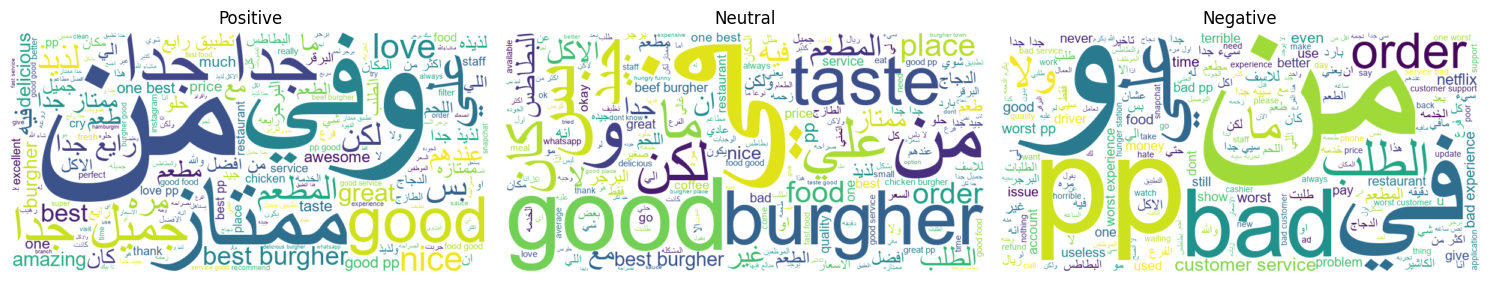

In [13]:
def clean_arabic_text(text):
    """Remove emojis and non-Arabic characters from the text."""
    cleaned_text = re.sub(r'[^\u0600-\u06FF\s]', '', text)
    return cleaned_text.strip()

def clean_english_text(text):
    """Remove emojis from English text."""
    cleaned_text = re.sub(r'[^\w\s]', '', text)
    return cleaned_text.strip()

# Create a word cloud for each sentiment class (Both English and Arabic)
sentiments = df['label'].unique()

# Set up the plot
plt.figure(figsize=(15, 10))

for i, sentiment in enumerate(sentiments):
    plt.subplot(1, len(sentiments), i + 1)
    
    # Combine reviews for the current sentiment from both languages
    en_text = ' '.join(en_df[en_df['label'] == sentiment]['review'].dropna().astype(str))
    ar_text = ' '.join(ar_df[ar_df['label'] == sentiment]['review'].dropna().astype(str))
    
    # Clean the texts
    cleaned_en_text = clean_english_text(en_text)
    cleaned_ar_text = clean_arabic_text(ar_text)
    
    # Reshape the Arabic text
    if cleaned_ar_text:
        reshaped_ar_text = arabic_reshaper.reshape(cleaned_ar_text)
        bidi_ar_text = get_display(reshaped_ar_text)
    else:
        bidi_ar_text = ''

    # Combine cleaned English and Arabic texts
    combined_text = cleaned_en_text + ' ' + bidi_ar_text
    
    # Generate the word cloud
    wordcloud = WordCloud(font_path='arial', width=800, height=400, background_color='white').generate(combined_text)
    
    # Display the word cloud
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')  # Hide axes
    plt.title(sentiment.capitalize())  # Title for each sentiment

# Show the plot
plt.tight_layout()
plt.show()

* N-gram Analysis (Bigrams and Trigrams)

In [472]:
# Function to clean and split text into words
def clean_text(text):
    # Remove non-alphanumeric characters and split into words
    words = re.findall(r'\b\w+\b', text.lower())
    return words

# Function to get n-grams
def get_ngrams(text, n):
    words = clean_text(text)
    return list(ngrams(words, n))

In [473]:
# Initialize dictionaries to hold n-gram counts for each sentiment
bigram_counts = {sentiment: Counter() for sentiment in df['label'].unique()}
trigram_counts = {sentiment: Counter() for sentiment in df['label'].unique()}

In [474]:
# Loop through the reviews and update n-gram counts by sentiment
for sentiment in df['label'].unique():
    current_reviews = df[df['label'] == sentiment]['review'].dropna().astype(str)
    for review in current_reviews:
        bigrams = get_ngrams(review, 2)
        trigrams = get_ngrams(review, 3)
        bigram_counts[sentiment].update(bigrams)
        trigram_counts[sentiment].update(trigrams)

In [475]:
# Prepare data for DataFrames
def create_ngram_dataframe(ngram_counts, n):
    ngram_rows = []
    for sentiment, counter in ngram_counts.items():
        for ngram, freq in counter.most_common(10):  # Top 10 n-grams
            ngram_str = ' '.join(ngram)
            ngram_rows.append({'Sentiment': sentiment, 'N-gram': ngram_str, 'Frequency': freq})
    return pd.DataFrame(ngram_rows)

In [476]:
# Create DataFrames for bigrams and trigrams
bigram_df = create_ngram_dataframe(bigram_counts, 2)
trigram_df = create_ngram_dataframe(trigram_counts, 3)

In [477]:
# Display the tables
print("Most Common Bigrams:")
print(bigram_df)

Most Common Bigrams:
   Sentiment            N-gram  Frequency
0   positive           جدا جدا        278
1   positive          جميل جدا        221
2   positive          رايع جدا        152
3   positive      best burgher        140
4   positive         ممتاز جدا        136
5   positive        تطبيق رايع        121
6   positive           من افضل        108
7   positive          لذيذ جدا        102
8   positive          one best         89
9   positive           good pp         88
10   neutral      best burgher         95
11   neutral      beef burgher         77
12   neutral           جدا جدا         59
13   neutral          one best         55
14   neutral           جيد جدا         52
15   neutral            لا باس         44
16   neutral          جميل جدا         43
17   neutral   chicken burgher         43
18   neutral           good pp         41
19   neutral           اكثر من         39
20  negative  customer service        260
21  negative           جدا جدا        160
22  negative 

In [478]:
print("Most Common Trigrams:")
print(trigram_df)

Most Common Trigrams:
   Sentiment                  N-gram  Frequency
0   positive             جدا جدا جدا        124
1   positive           من افضل مطاعم         47
2   positive        one best burgher         40
3   positive          تطبيق رايع جدا         37
4   positive            جميل جدا جدا         36
5   positive            رايع جدا جدا         33
6   positive             ما شاء الله         32
7   positive          غني عن التعريف         28
8   positive          تطبيق جميل جدا         27
9   positive           ممتاز جدا جدا         24
10   neutral        one best burgher         30
11   neutral               لا باس به         22
12   neutral       best burgher town         21
13   neutral       best beef burgher         19
14   neutral             جدا جدا جدا         18
15   neutral       best burgher ever         15
16   neutral        مطعم وجبات سريعه         14
17   neutral      الاسعار مبالغ فيها         12
18   neutral             اكثر من مره         11
19   neutral      

* Word Frequency Analysis (Tables for Arabic and English)

In [479]:
# Function to clean and split text into words
def clean_text(text):
    # Remove non-alphanumeric characters and split into words
    words = re.findall(r'\b\w+\b', text.lower())
    return words

In [480]:
# Initialize dictionaries to hold word counts for each sentiment
word_counts = {
    'arabic': {sentiment: Counter() for sentiment in df['label'].unique()},
    'english': {sentiment: Counter() for sentiment in df['label'].unique()}
}

In [481]:
# Loop through the reviews and update word counts by sentiment
for sentiment in df['label'].unique():
    current_reviews = df[df['label'] == sentiment]['review'].dropna().astype(str)
    for review in current_reviews:
        words = clean_text(review)
        if any('\u0600' <= char <= '\u06FF' for char in review):  # Check for Arabic characters
            word_counts['arabic'][sentiment].update(words)
        else:
            word_counts['english'][sentiment].update(words)

In [482]:
# Prepare data for Arabic DataFrame
arabic_common_words_data = {}
num_common_words = 10  # Number of common words to display

for sentiment, counter in word_counts['arabic'].items():
    arabic_common_words_data[sentiment] = counter.most_common(num_common_words)

In [483]:
# Create DataFrame for Arabic common words
arabic_rows = []
for sentiment, common_words in arabic_common_words_data.items():
    for word, freq in common_words:
        arabic_rows.append({'Sentiment': sentiment, 'Word': word, 'Frequency': freq})

arabic_common_words_df = pd.DataFrame(arabic_rows)

In [484]:
# Prepare data for English DataFrame
english_common_words_data = {}

for sentiment, counter in word_counts['english'].items():
    english_common_words_data[sentiment] = counter.most_common(num_common_words)

In [485]:
# Create DataFrame for English common words
english_rows = []
for sentiment, common_words in english_common_words_data.items():
    for word, freq in common_words:
        english_rows.append({'Sentiment': sentiment, 'Word': word, 'Frequency': freq})

english_common_words_df = pd.DataFrame(english_rows)

In [486]:
# Display the tables
print("Most Common Words in Arabic Reviews:\n")
print(arabic_common_words_df)

Most Common Words in Arabic Reviews:

   Sentiment   Word  Frequency
0   positive    جدا       1476
1   positive     من        811
2   positive   لذيذ        632
3   positive  ممتاز        616
4   positive      و        604
5   positive   جميل        577
6   positive     في        570
7   positive   رايع        519
8   positive  تطبيق        351
9   positive   افضل        308
10   neutral    جدا        493
11   neutral     في        484
12   neutral     من        465
13   neutral    لكن        372
14   neutral     بس        361
15   neutral    جيد        333
16   neutral      و        321
17   neutral  ممتاز        242
18   neutral     ما        217
19   neutral   لذيذ        199
20  negative     من       1020
21  negative    جدا        935
22  negative     في        695
23  negative      و        541
24  negative  الطلب        480
25  negative     ما        395
26  negative    سيء        392
27  negative    علي        358
28  negative    غير        358
29  negative    ولا        339


In [487]:
print("Most Common Words in English Reviews:\n")
print(english_common_words_df)

Most Common Words in English Reviews:

   Sentiment        Word  Frequency
0   positive        good       1124
1   positive     burgher        688
2   positive          pp        569
3   positive        best        525
4   positive        food        441
5   positive        love        325
6   positive       great        315
7   positive       taste        291
8   positive        nice        284
9   positive     service        281
10   neutral     burgher        757
11   neutral        good        745
12   neutral        food        371
13   neutral          pp        333
14   neutral       taste        319
15   neutral        like        292
16   neutral        best        290
17   neutral       order        280
18   neutral       place        271
19   neutral     service        256
20  negative         bad       1010
21  negative          pp        980
22  negative       worst        687
23  negative     service        675
24  negative       order        621
25  negative    customer 

In [489]:
df.to_csv('complete_dataset.csv',encoding='utf-8-sig',index=False)